In [1]:
#0
!apt-get -qq install -y tesseract-ocr tesseract-ocr-fra > /dev/null
!pip -q install reportlab pdfplumber pymupdf pytesseract opencv-python-headless transformers accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
#1
from pathlib import Path
import json, random, io, re, time, unicodedata, difflib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE = Path("/content/labmind")
for d in ["pdf_digital", "pdf_scanned", "ground_truth", "uploads", "outputs/reports"]:
    (BASE / d).mkdir(parents=True, exist_ok=True)
print("Dossier de travail :", BASE)

Dossier de travail : /content/labmind


In [3]:
#2
random.seed(42)
CATALOG = {
 "HGB": {"cat":"NFS","aliases":["Hémoglobine","HGB","Hb"],"unit":"g/dL","ref":(12.0,16.0)},
 "WBC": {"cat":"NFS","aliases":["Globules blancs","Leucocytes","WBC"],"unit":"10^3/µL","ref":(4.0,10.0)},
 "RBC": {"cat":"NFS","aliases":["Globules rouges","Hématies","RBC"],"unit":"10^6/µL","ref":(4.0,5.5)},
 "PLT": {"cat":"NFS","aliases":["Plaquettes","PLT"],"unit":"10^3/µL","ref":(150,400)},
 "HCT": {"cat":"NFS","aliases":["Hématocrite","HCT"],"unit":"%","ref":(37,47)},
 "GLY": {"cat":"Glycémie","aliases":["Glycémie","Glycémie à jeun","Glucose"],"unit":"g/L","ref":(0.70,1.10)},
 "CHOL":{"cat":"Lipides","aliases":["Cholestérol total","Cholestérol"],"unit":"g/L","ref":(1.40,2.00)},
 "HDL": {"cat":"Lipides","aliases":["HDL","Cholestérol HDL"],"unit":"g/L","ref":(0.40,0.60)},
 "LDL": {"cat":"Lipides","aliases":["LDL","Cholestérol LDL"],"unit":"g/L","ref":(0.60,1.30)},
 "TG":  {"cat":"Lipides","aliases":["Triglycérides","TG"],"unit":"g/L","ref":(0.40,1.50)},
}
LABS = ["Laboratoire Alpha","Biolab Centre","Laboratoire El Manar","Analyses Médicales Sud"]

def status(v, lo, hi):
    if lo is None or hi is None: return "reference_unavailable"
    if v < lo: return "below_reference"
    if v > hi: return "above_reference"
    return "within_reference"

def make_report_data(doc_id):
    cats = random.sample(["NFS","Glycémie","Lipides"], k=random.randint(1,3))
    codes = [c for c,p in CATALOG.items() if p["cat"] in cats]
    use_mgdl = random.random() < 0.25
    params = []
    for code in codes:
        p = CATALOG[code]; lo, hi = p["ref"]; unit = p["unit"]
        r = random.random()
        v = random.uniform(lo, hi) if r < .6 else (random.uniform(lo*0.7, lo*0.98) if r < .8 else random.uniform(hi*1.02, hi*1.4))
        if use_mgdl and p["unit"]=="g/L":
            lo, hi, v, unit = lo*100, hi*100, v*100, "mg/dL"
        nd = 0 if (p["unit"] in ("10^3/µL","%") or unit=="mg/dL") else 2
        if code in ("HGB","WBC","RBC"): nd = 1
        v, lo, hi = round(v,nd), round(lo,nd), round(hi,nd)
        entry = {"code":code, "name_printed":random.choice(p["aliases"]),
                 "value":v, "unit":unit, "reference_min":lo, "reference_max":hi}
        e = random.random()
        if e < 0.05:   entry["unit"] = None; entry["error"]="missing_unit"
        elif e < 0.10: entry["reference_min"]=entry["reference_max"]=None; entry["error"]="missing_reference"
        entry["status"] = status(v, entry["reference_min"], entry["reference_max"])
        params.append(entry)
    return {"doc_id":doc_id, "lab":random.choice(LABS),
            "layout":random.choice(["table1","table2","lines"]),
            "decimal_comma": random.random()<0.6, "parameters":params}

In [4]:
#3
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Table, TableStyle, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors
import pymupdf
from PIL import Image, ImageFilter

def fmt(x, comma):
    if x is None: return ""
    s = str(x)
    return s.replace(".", ",") if comma else s

def ref_str(p, comma):
    if p["reference_min"] is None: return ""
    return f'{fmt(p["reference_min"],comma)} - {fmt(p["reference_max"],comma)}'

def render_pdf(data, path):
    st = getSampleStyleSheet(); c = data["decimal_comma"]
    els = [Paragraph(f'<b>{data["lab"]}</b>', st["Title"]),
           Paragraph(f'Compte rendu fictif n° {data["doc_id"]} - Patient : TEST ANONYME', st["Normal"]),
           Spacer(1,20)]
    P = data["parameters"]
    if data["layout"] == "table1":
        rows = [["Examen","Résultat","Unité","Valeurs de référence"]] + [[p["name_printed"], fmt(p["value"],c), p["unit"] or "", ref_str(p,c)] for p in P]
    elif data["layout"] == "table2":
        rows = [["Paramètre","Valeurs usuelles","Résultat","Unité"]] + [[p["name_printed"], ref_str(p,c), fmt(p["value"],c), p["unit"] or ""] for p in P]
    if data["layout"] in ("table1","table2"):
        t = Table(rows, hAlign="LEFT")
        t.setStyle(TableStyle([("GRID",(0,0),(-1,-1),0.5,colors.grey),("BACKGROUND",(0,0),(-1,0),colors.lightgrey)]))
        els.append(t)
    else:
        for p in P:
            ref = f' (réf. : {ref_str(p,c)})' if p["reference_min"] is not None else ""
            els.append(Paragraph(f'{p["name_printed"]} : {fmt(p["value"],c)} {p["unit"] or ""}{ref}', st["Normal"]))
    SimpleDocTemplate(str(path), pagesize=A4).build(els)

def to_scan(pdf_path, out_path, quality):
    page = pymupdf.open(pdf_path)[0]
    img = Image.open(io.BytesIO(page.get_pixmap(dpi=quality["dpi"]).tobytes("png"))).convert("L")
    img = img.rotate(random.uniform(-quality["rot"], quality["rot"]), expand=True, fillcolor=255)
    if quality["blur"]: img = img.filter(ImageFilter.GaussianBlur(quality["blur"]))
    img.save(out_path)

QUALITIES = {"bonne":{"dpi":200,"rot":0.5,"blur":0},
             "moyenne":{"dpi":120,"rot":1.5,"blur":0.6},
             "mauvaise":{"dpi":80,"rot":3,"blur":1.2}}

In [5]:
#4
for i in range(1, 101):
    d = make_report_data(i)
    render_pdf(d, BASE / "pdf_digital" / f"doc_{i:03d}.pdf")
    with open(BASE / "ground_truth" / f"doc_{i:03d}.json", "w", encoding="utf-8") as f:
        json.dump(d, f, ensure_ascii=False, indent=2)
for i in range(1, 41):
    q = random.choice(list(QUALITIES))
    to_scan(BASE / "pdf_digital" / f"doc_{i:03d}.pdf", BASE / "pdf_scanned" / f"doc_{i:03d}_{q}.png", QUALITIES[q])
for d in ["pdf_digital", "pdf_scanned", "ground_truth"]:
    print(d, "->", len(list((BASE / d).iterdir())), "fichiers")

pdf_digital -> 100 fichiers
pdf_scanned -> 40 fichiers
ground_truth -> 100 fichiers


Documents : 100 | Paramètres : 671

-- Paramètres par code --
code
GLY     70
HGB     69
WBC     69
RBC     69
PLT     69
HCT     69
CHOL    64
HDL     64
LDL     64
TG      64

-- Statuts --
status
within_reference         372
above_reference          129
below_reference          126
reference_unavailable     44

-- Unités --
unit
g/L        234
10^3/µL    130
mg/dL       85
%           68
g/dL        67
10^6/µL     66
None        21

-- Mises en page --
layout
table2    39
lines     36
table1    25

-- Virgule décimale --
decimal_comma
True     63
False    37

-- Cas d'erreur volontaires --
error
NaN                  606
missing_reference     44
missing_unit          21

-- Alias par paramètre --
CHOL  -> ['Cholestérol', 'Cholestérol total']
GLY   -> ['Glycémie à jeun', 'Glycémie', 'Glucose']
HCT   -> ['Hématocrite', 'HCT']
HDL   -> ['HDL', 'Cholestérol HDL']
HGB   -> ['Hb', 'HGB', 'Hémoglobine']
LDL   -> ['Cholestérol LDL', 'LDL']
PLT   -> ['Plaquettes', 'PLT']
RBC   -> ['RBC', 'Hém

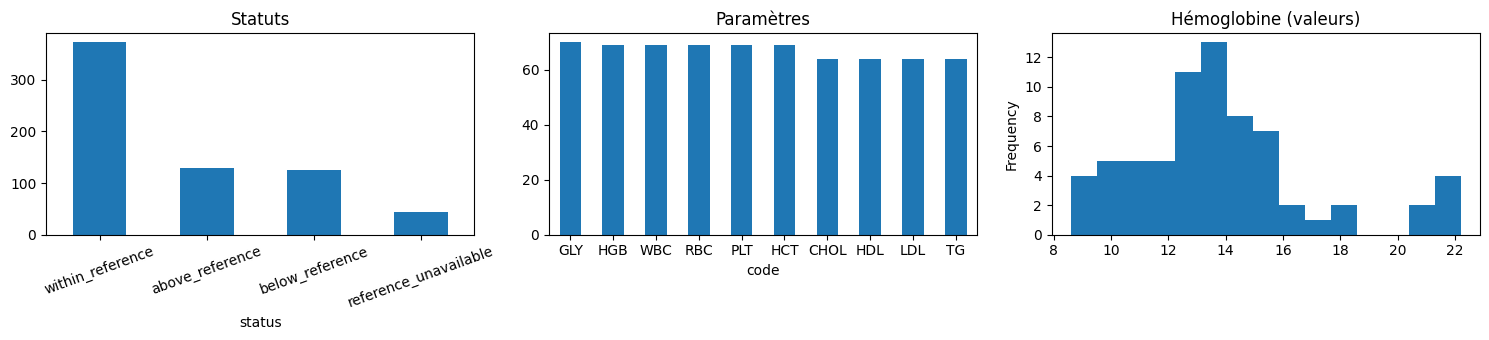

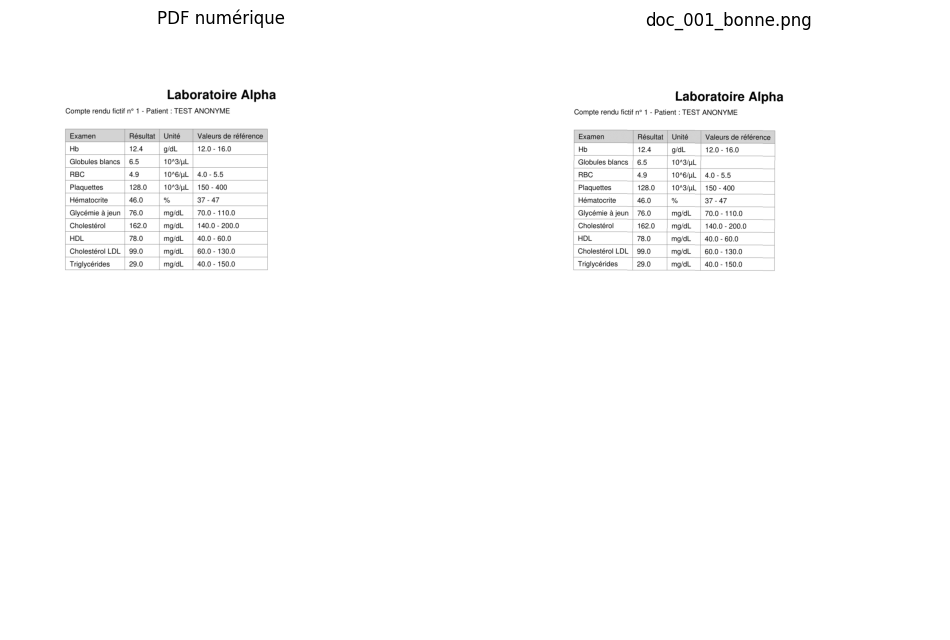

In [6]:
#5
rows = []
for f in sorted((BASE / "ground_truth").glob("*.json")):
    d = json.load(open(f, encoding="utf-8"))
    for p in d["parameters"]:
        rows.append({"doc_id": d["doc_id"], "lab": d["lab"], "layout": d["layout"],
                     "decimal_comma": d["decimal_comma"], **p})
df = pd.DataFrame(rows)
if "error" not in df: df["error"] = None

print("Documents :", df.doc_id.nunique(), "| Paramètres :", len(df))
print("\n-- Paramètres par code --"); print(df.code.value_counts().to_string())
print("\n-- Statuts --"); print(df.status.value_counts().to_string())
print("\n-- Unités --"); print(df.unit.value_counts(dropna=False).to_string())
docs = df.drop_duplicates("doc_id")
print("\n-- Mises en page --"); print(docs.layout.value_counts().to_string())
print("\n-- Virgule décimale --"); print(docs.decimal_comma.value_counts().to_string())
print("\n-- Cas d'erreur volontaires --"); print(df.error.value_counts(dropna=False).to_string())
print("\n-- Alias par paramètre --")
for code_, names in df.groupby("code").name_printed.unique().items():
    print(f"{code_:5s} -> {list(names)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
df.status.value_counts().plot(kind="bar", ax=ax[0], title="Statuts", rot=20)
df.code.value_counts().plot(kind="bar", ax=ax[1], title="Paramètres", rot=0)
df[df.code == "HGB"].value.plot(kind="hist", ax=ax[2], bins=15, title="Hémoglobine (valeurs)")
plt.tight_layout(); plt.show()

pdf_img = Image.open(io.BytesIO(pymupdf.open(BASE / "pdf_digital/doc_001.pdf")[0].get_pixmap(dpi=100).tobytes("png")))
scan_file = sorted((BASE / "pdf_scanned").glob("doc_001_*.png"))[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax[0].imshow(pdf_img); ax[0].set_title("PDF numérique"); ax[0].axis("off")
ax[1].imshow(Image.open(scan_file), cmap="gray"); ax[1].set_title(scan_file.name); ax[1].axis("off")
plt.show()

In [7]:
#6
ALIASES = {
    "HGB": ["Hémoglobine", "HGB", "Hb"],
    "WBC": ["Globules blancs", "Leucocytes", "WBC"],
    "RBC": ["Globules rouges", "Hématies", "RBC"],
    "PLT": ["Plaquettes", "PLT"],
    "HCT": ["Hématocrite", "HCT"],
    "GLY": ["Glycémie à jeun", "Glycémie", "Glucose"],
    "CHOL": ["Cholestérol total", "Cholestérol"],
    "HDL": ["Cholestérol HDL", "HDL"],
    "LDL": ["Cholestérol LDL", "LDL"],
    "TG": ["Triglycérides", "TG"],
}
KNOWN_UNITS = ["g/dL", "g/L", "mg/dL", "%", "10^3/µL", "10^6/µL"]
NUM = r"\d+(?:[.,]\d+)?"
RANGE_RE = re.compile(rf"({NUM})\s*[-–—]\s*({NUM})")
NUM_RE = re.compile(NUM)

def _norm(s):
    s = unicodedata.normalize("NFD", s.lower())
    return "".join(c for c in s if unicodedata.category(c) != "Mn")

_ALIAS_LIST = sorted(((_norm(a), code) for code, al in ALIASES.items() for a in al), key=lambda x: -len(x[0]))

def to_float(s):
    return float(s.replace(",", "."))

def normalize_unit(u):
    """Nettoie l'unité et corrige les erreurs OCR (10%3/uL -> 10^3/µL)."""
    if not u: return None
    u = u.strip().strip("()[]:;|_")
    u = re.sub(r"\s+", "", u).replace("μ", "µ")
    if not u: return None
    low = u.lower().replace("µ", "u")
    exact = {k.lower().replace("µ", "u"): k for k in KNOWN_UNITS}
    if low in exact: return exact[low]
    m = re.match(r"^10\W?([36])/\w*l$", low)
    if m: return f"10^{m.group(1)}/µL"
    cand = difflib.get_close_matches(low, list(exact), n=1, cutoff=0.7)
    return exact[cand[0]] if cand else u

def match_alias(line):
    n = _norm(line)
    for alias, code in _ALIAS_LIST:
        if re.match(rf"^{re.escape(alias)}(?=[\s:;|]|$)", n):
            return code, alias
    return None, None

def parse_line(line):
    code, alias = match_alias(line)
    if code is None: return None
    rest = line[len(alias):].lstrip(" :;|") if len(line) >= len(alias) else ""
    ref_min = ref_max = None
    m = RANGE_RE.search(rest)
    if m:
        ref_min, ref_max = to_float(m.group(1)), to_float(m.group(2))
        rest = rest[:m.start()] + " " + rest[m.end():]
    rest = re.sub(r"\(\s*r[ée]f\.?\s*:?\s*\)", " ", rest, flags=re.I)
    mv = NUM_RE.search(rest)
    if not mv: return None
    value = to_float(mv.group(0))
    unit_txt = (rest[:mv.start()] + " " + rest[mv.end():]).strip()
    unit = normalize_unit(unit_txt) if unit_txt else None
    return {"code": code, "name_printed": line[:len(alias)].strip(), "value": value, "unit": unit,
            "reference_min": ref_min, "reference_max": ref_max, "raw_line": line.strip()}

def identify_parameters(text):
    out = []
    for line in text.splitlines():
        line = line.strip()
        if line:
            p = parse_line(line)
            if p: out.append(p)
    return out

for t in ["Hb 12,4 g/dL 12,0 - 16,0", "Glycémie 0,7 - 1,1 0,85 g/L",
          "Cholestérol LDL : 122.0 mg/dL (réf. : 60.0 - 130.0)",
          "Hématocrite 46.0 12.0 - 47.0", "Plaquettes 128.0 10^3/µL"]:
    print(t, "\n   ->", identify_parameters(t))

Hb 12,4 g/dL 12,0 - 16,0 
   -> [{'code': 'HGB', 'name_printed': 'Hb', 'value': 12.4, 'unit': 'g/dL', 'reference_min': 12.0, 'reference_max': 16.0, 'raw_line': 'Hb 12,4 g/dL 12,0 - 16,0'}]
Glycémie 0,7 - 1,1 0,85 g/L 
   -> [{'code': 'GLY', 'name_printed': 'Glycémie', 'value': 0.85, 'unit': 'g/L', 'reference_min': 0.7, 'reference_max': 1.1, 'raw_line': 'Glycémie 0,7 - 1,1 0,85 g/L'}]
Cholestérol LDL : 122.0 mg/dL (réf. : 60.0 - 130.0) 
   -> [{'code': 'LDL', 'name_printed': 'Cholestérol LDL', 'value': 122.0, 'unit': 'mg/dL', 'reference_min': 60.0, 'reference_max': 130.0, 'raw_line': 'Cholestérol LDL : 122.0 mg/dL (réf. : 60.0 - 130.0)'}]
Hématocrite 46.0 12.0 - 47.0 
   -> [{'code': 'HCT', 'name_printed': 'Hématocrite', 'value': 46.0, 'unit': None, 'reference_min': 12.0, 'reference_max': 47.0, 'raw_line': 'Hématocrite 46.0 12.0 - 47.0'}]
Plaquettes 128.0 10^3/µL 
   -> [{'code': 'PLT', 'name_printed': 'Plaquettes', 'value': 128.0, 'unit': '10^3/µL', 'reference_min': None, 'reference_ma

In [8]:
#7
import pytesseract, numpy as np, cv2, pdfplumber

def ocr_lang():
    try:
        return "fra" if "fra" in pytesseract.get_languages() else "eng"
    except Exception:
        return "eng"

def preprocess(img):
    """Niveaux de gris, agrandissement, binarisation, suppression des lignes de tableau."""
    g = np.array(img.convert("L"))
    if g.shape[1] < 1600:
        f = 1600 / g.shape[1]
        g = cv2.resize(g, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    h = cv2.morphologyEx(bw, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (60, 1)))
    v = cv2.morphologyEx(bw, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, 40)))
    bw = cv2.subtract(bw, cv2.add(h, v))
    return Image.fromarray(255 - bw)

def ocr_image(img):
    return pytesseract.image_to_string(preprocess(img), lang=ocr_lang(), config="--psm 6")

def extract_document(path, min_chars=30):
    """Retourne {"text", "method"} ; method = 'pdf_text' ou 'ocr'."""
    path = Path(path); suffix = path.suffix.lower()
    if suffix == ".pdf":
        with pdfplumber.open(path) as pdf:
            text = "\n".join((p.extract_text() or "") for p in pdf.pages)
        if len(text.strip()) >= min_chars:
            return {"text": text, "method": "pdf_text"}
        texts = []
        for page in pymupdf.open(path):
            texts.append(ocr_image(Image.open(io.BytesIO(page.get_pixmap(dpi=200).tobytes("png")))))
        return {"text": "\n".join(texts), "method": "ocr"}
    if suffix in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
        return {"text": ocr_image(Image.open(path)), "method": "ocr"}
    raise ValueError(f"Format non supporté : {suffix}")

print("Langue OCR utilisée :", ocr_lang())
r = extract_document(BASE / "pdf_digital/doc_001.pdf")
print(r["method"]); print(r["text"])

Langue OCR utilisée : fra
pdf_text
Laboratoire Alpha
Compte rendu fictif n° 1 - Patient : TEST ANONYME
Examen Résultat Unité Valeurs de référence
Hb 12.4 g/dL 12.0 - 16.0
Globules blancs 6.5 10^3/µL
RBC 4.9 10^6/µL 4.0 - 5.5
Plaquettes 128.0 10^3/µL 150 - 400
Hématocrite 46.0 % 37 - 47
Glycémie à jeun 76.0 mg/dL 70.0 - 110.0
Cholestérol 162.0 mg/dL 140.0 - 200.0
HDL 78.0 mg/dL 40.0 - 60.0
Cholestérol LDL 99.0 mg/dL 60.0 - 130.0
Triglycérides 29.0 mg/dL 40.0 - 150.0


In [9]:
#8
def _eq(a, b):
    if a is None or b is None: return a is None and b is None
    if isinstance(a, (int, float)) and isinstance(b, (int, float)): return abs(a - b) < 1e-6
    return a == b

def evaluate_document(extracted, truth_params):
    ext = {p["code"]: p for p in extracted}
    r = {"truth": len(truth_params), "found": 0, "value_ok": 0, "unit_ok": 0, "ref_ok": 0, "all_ok": 0}
    for t in truth_params:
        e = ext.get(t["code"])
        if e is None: continue
        r["found"] += 1
        v = _eq(e["value"], t["value"]); u = _eq(e["unit"], t["unit"])
        f = _eq(e["reference_min"], t["reference_min"]) and _eq(e["reference_max"], t["reference_max"])
        r["value_ok"] += v; r["unit_ok"] += u; r["ref_ok"] += f; r["all_ok"] += (v and u and f)
    return r

def run_eval(files):
    rows = []
    for f in files:
        truth = json.load(open(BASE / "ground_truth" / f"doc_{f.stem.split('_')[1]}.json", encoding="utf-8"))
        ex = extract_document(f)
        rows.append({"file": f.name, **evaluate_document(identify_parameters(ex["text"]), truth["parameters"])})
    return pd.DataFrame(rows)

def summary(d):
    t = d.truth.sum()
    return pd.Series({"attendus": t, "rappel": round(d.found.sum()/t, 3), "valeur": round(d.value_ok.sum()/t, 3),
                      "unité": round(d.unit_ok.sum()/t, 3), "référence": round(d.ref_ok.sum()/t, 3),
                      "tout correct": round(d.all_ok.sum()/t, 3)})

dig = run_eval(sorted((BASE / "pdf_digital").glob("*.pdf")))
print("PDF NUMÉRIQUES"); print(summary(dig).to_string())
sc = run_eval(sorted((BASE / "pdf_scanned").glob("*.png")))
sc["qualite"] = sc.file.str.extract(r"_(bonne|moyenne|mauvaise)")[0]
print("\nSCANS par qualité"); print(sc.groupby("qualite").apply(summary).to_string())

PDF NUMÉRIQUES
attendus        671.0
rappel            1.0
valeur            1.0
unité             1.0
référence         1.0
tout correct      1.0

SCANS par qualité
          attendus  rappel  valeur  unité  référence  tout correct
qualite                                                           
bonne         68.0   0.926   0.868  0.779      0.868         0.691
mauvaise      78.0   0.000   0.000  0.000      0.000         0.000
moyenne       96.0   0.885   0.667  0.698      0.781         0.573


/tmp/ipykernel_385/2287640106.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print("\nSCANS par qualité"); print(sc.groupby("qualite").apply(summary).to_string())


In [10]:
#9
SOURCE_TODO = {"title": "À COMPLÉTER", "organisme": "", "reference": "", "date_verification": None, "validated": False}

def _e(code, name, cat, what, units, questions):
    return {"code": code, "name_fr": name, "category": cat, "what_it_measures": what, "accepted_units": units,
            "doctor_questions": questions, "source": dict(SOURCE_TODO)}

KB = {e["code"]: e for e in [
    _e("HGB", "Hémoglobine", "NFS", "Protéine des globules rouges qui transporte l'oxygène dans le sang.", ["g/dL", "g/L"],
       ["Ce résultat est-il à interpréter avec mon âge, mon sexe et mon état de santé ?", "Faut-il refaire ou compléter cette analyse ?"]),
    _e("WBC", "Globules blancs", "NFS", "Cellules du sang qui participent aux défenses de l'organisme.", ["10^3/µL"],
       ["Ce résultat peut-il être lié à un événement récent (fatigue, fièvre, infection) ?", "Faut-il refaire cette analyse ?"]),
    _e("RBC", "Globules rouges", "NFS", "Cellules du sang qui transportent l'oxygène.", ["10^6/µL"],
       ["Ce résultat est-il cohérent avec mon hémoglobine et mon hématocrite ?"]),
    _e("PLT", "Plaquettes", "NFS", "Petites cellules du sang qui participent à la coagulation.", ["10^3/µL"],
       ["Ce résultat nécessite-t-il un contrôle ou un autre examen ?"]),
    _e("HCT", "Hématocrite", "NFS", "Part du volume du sang occupée par les globules rouges.", ["%"],
       ["Ce résultat est-il cohérent avec mon hémoglobine et mes globules rouges ?"]),
    _e("GLY", "Glycémie", "Glycémie", "Concentration de glucose (sucre) dans le sang.", ["g/L", "mg/dL"],
       ["Ce résultat tient-il compte de mon jeûne au moment du prélèvement ?", "Faut-il refaire la mesure ou faire un autre examen ?"]),
    _e("CHOL", "Cholestérol total", "Lipides", "Ensemble des cholestérols du sang (graisses utilisées par l'organisme).", ["g/L", "mg/dL"],
       ["Ce résultat doit-il être lu avec mon HDL, mon LDL et mes triglycérides ?", "Dois-je refaire un bilan complet ?"]),
    _e("HDL", "Cholestérol HDL", "Lipides", "Forme de cholestérol souvent appelée « bon cholestérol ».", ["g/L", "mg/dL"],
       ["Comment ce résultat s'interprète-t-il avec le reste de mon bilan lipidique ?"]),
    _e("LDL", "Cholestérol LDL", "Lipides", "Forme de cholestérol souvent appelée « mauvais cholestérol ».", ["g/L", "mg/dL"],
       ["Comment ce résultat s'interprète-t-il avec le reste de mon bilan lipidique ?"]),
    _e("TG", "Triglycérides", "Lipides", "Graisses du sang, liées notamment à l'alimentation.", ["g/L", "mg/dL"],
       ["Ce résultat dépend-il de mon dernier repas ? Faut-il refaire la mesure à jeun ?"]),
]}

# Message médical UNIQUE (ajouté une seule fois, à la fin du rapport, par le code)
DOCTOR_MSG = ("⚠️ Outil pédagogique : ce bilan ne remplace pas une consultation médicale et ne constitue ni un diagnostic "
              "ni une prescription. Faites interpréter vos résultats par un médecin.")

STATUS_FR = {"below_reference": "en dessous de la fourchette du laboratoire", "within_reference": "dans la fourchette du laboratoire",
             "above_reference": "au-dessus de la fourchette du laboratoire",
             "reference_unavailable": "comparaison impossible : fourchette absente du document", "value_unavailable": "valeur absente"}
VERDICT = {"within_reference": "Dans la fourchette", "below_reference": "En dessous", "above_reference": "Au-dessus", "reference_unavailable": "Fourchette absente"}
ICON = {"within_reference": "✅", "below_reference": "⬇️", "above_reference": "⬆️", "reference_unavailable": "❔"}
POSITION = {"below_reference": "en dessous de la fourchette du laboratoire", "above_reference": "au-dessus de la fourchette du laboratoire"}

# ---- Conseils concrets, rédigés et FIGÉS dans la base (aucun médicament, complément ni régime). Catégories : food / move / know.
# À faire relire par un professionnel (diététicien, médecin) et à sourcer avant la démonstration finale.
IRON_LOW = [
 ("food", "Misez sur les aliments riches en fer : lentilles, pois chiches, haricots secs, épinards, viande rouge, volaille, poisson."),
 ("food", "Associez-les à un fruit ou légume riche en vitamine C (orange, citron, kiwi, poivron) : cela aide à mieux absorber le fer."),
 ("food", "Buvez le thé et le café en dehors des repas : ils réduisent l'absorption du fer."),
 ("move", "Gardez une activité douce comme la marche et adaptez l'effort à votre fatigue."),
 ("know", "Une valeur basse peut avoir des causes très variées : elle se lit avec l'ensemble du bilan.")]
BLOOD_HIGH = [
 ("food", "Buvez de l'eau régulièrement tout au long de la journée."),
 ("know", "Une déshydratation passagère peut faire monter ces valeurs : pensez à bien vous hydrater avant une prise de sang.")]
SUGAR_HIGH = [
 ("food", "Remplacez les boissons sucrées et les jus industriels par de l'eau."),
 ("food", "Limitez les pâtisseries et les sucreries ; préférez légumes, légumineuses et céréales complètes."),
 ("food", "Mangez les fruits entiers plutôt qu'en jus."),
 ("move", "Marchez 10 à 15 minutes après les repas : c'est simple et utile pour la glycémie."),
 ("know", "La glycémie dépend du jeûne : précisez si vous étiez à jeun lors du prélèvement.")]
SUGAR_LOW = [
 ("food", "Ne sautez pas de repas et mangez régulièrement dans la journée."),
 ("know", "En cas de malaise, de sueurs, de tremblements ou de vertiges, n'attendez pas : demandez rapidement de l'aide médicale.")]
LIPID_HIGH = [
 ("food", "Remplacez les graisses saturées (beurre, charcuterie, fritures, viennoiseries) par de l'huile d'olive, des noix et du poisson."),
 ("food", "Ajoutez des fibres : avoine, légumineuses, légumes, fruits, céréales complètes."),
 ("move", "Visez environ 30 minutes d'activité modérée la plupart des jours : marche rapide, vélo ou natation."),
 ("know", "Un seul résultat ne suffit pas : l'évolution dans le temps et l'ensemble du bilan comptent.")]
TG_HIGH = [
 ("food", "Limitez les boissons sucrées, les sucreries, les pâtisseries et l'alcool : ils font monter les triglycérides."),
 ("food", "Privilégiez le poisson (surtout gras, 2 fois par semaine), les légumes et les céréales complètes."),
 ("move", "Visez environ 30 minutes d'activité modérée la plupart des jours."),
 ("know", "Les triglycérides montent après un repas : un prélèvement à jeun donne un résultat plus fiable.")]
HDL_LOW = [
 ("food", "Privilégiez l'huile d'olive, les noix et le poisson gras."),
 ("move", "Une activité régulière (marche rapide, vélo, natation) est l'habitude la plus associée à un HDL plus élevé."),
 ("know", "Arrêter le tabac, si vous fumez, fait aussi partie des habitudes associées à un meilleur HDL.")]
WBC_ANY = [("know", "Les globules blancs varient avec la fatigue, le stress, une infection récente ou un effort intense : notez tout symptôme ou événement récent.")]
PLT_ANY = [("know", "Notez tout saignement inhabituel, bleu fréquent ou événement récent : cela aide à interpréter ce résultat.")]
CHOL_LOW = [("know", "Ce résultat se lit avec le reste du bilan : HDL, LDL et triglycérides.")]
DEFAULT_KNOW = [("know", "Ce résultat se lit avec l'ensemble de votre bilan et de votre situation.")]
NO_REF = [("know", "Demandez la fourchette de référence à votre laboratoire : sans elle, la comparaison est impossible.")]

TIPS = {
    "HGB": {"below_reference": IRON_LOW, "above_reference": BLOOD_HIGH},
    "RBC": {"below_reference": IRON_LOW, "above_reference": BLOOD_HIGH},
    "HCT": {"below_reference": IRON_LOW, "above_reference": BLOOD_HIGH},
    "GLY": {"above_reference": SUGAR_HIGH, "below_reference": SUGAR_LOW},
    "CHOL": {"above_reference": LIPID_HIGH, "below_reference": CHOL_LOW}, "LDL": {"above_reference": LIPID_HIGH},
    "TG": {"above_reference": TG_HIGH}, "HDL": {"below_reference": HDL_LOW},
    "WBC": {"below_reference": WBC_ANY, "above_reference": WBC_ANY}, "PLT": {"below_reference": PLT_ANY, "above_reference": PLT_ANY},
}
def tips_for(code, status):
    if status == "reference_unavailable": return NO_REF
    if status in ("below_reference", "above_reference"): return TIPS.get(code, {}).get(status, DEFAULT_KNOW)
    return []

json.dump(KB, open(BASE / "knowledge_base.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(len(KB), "paramètres dans la base")

10 paramètres dans la base


In [11]:
#10
def classify(value, ref_min, ref_max):
    if value is None: return "value_unavailable"
    if ref_min is None or ref_max is None: return "reference_unavailable"
    if value < ref_min: return "below_reference"
    if value > ref_max: return "above_reference"
    return "within_reference"

def check_parameter(p, accepted_units):
    issues = []
    if p.get("value") is None:
        issues.append({"code": p["code"], "issue": "missing_value", "blocking": True})
    if not p.get("unit"):
        issues.append({"code": p["code"], "issue": "missing_unit", "blocking": True})
    elif accepted_units and p["unit"] not in accepted_units:
        issues.append({"code": p["code"], "issue": "unexpected_unit", "blocking": True, "detail": p["unit"]})
    if p.get("reference_min") is None or p.get("reference_max") is None:
        issues.append({"code": p["code"], "issue": "missing_reference", "blocking": False})
    elif p["reference_min"] >= p["reference_max"]:
        issues.append({"code": p["code"], "issue": "invalid_reference", "blocking": True})
    return issues

assert classify(60, 70, 100) == "below_reference"
assert classify(95, 70, 100) == "within_reference"
assert classify(100, 70, 100) == "within_reference"
assert classify(120, 70, 100) == "above_reference"
assert classify(95, None, None) == "reference_unavailable"
assert classify(None, 70, 100) == "value_unavailable"
print("Tests du système expert : OK")

Tests du système expert : OK


In [12]:
#11
FORBIDDEN_WORDS = ["diagnostic de", "vous avez une maladie", "vous souffrez", "vous êtes malade", "pronostic", "diabète", "anémie",
                   "carence", "manque de", "déficit", "insuline", "statine", "antibiotique", "complément", "supplément", "gélule",
                   "comprimé", "cure", "détox", "régime", "posologie", "dosage", "jeûner",
                   "médecin", "docteur", "consultez", "consultation", "professionnel de santé"]   # le message médical est ajouté UNE fois par le code
FORBIDDEN_IMPERATIVES = r"\b(prenez|prends|arrêtez|commencez|suivez un)\b"
QUANTITY_RE = r"\b(minutes?|heures?|fois par|par jour|par semaine|par mois|kg|kilos?|grammes?|litres?|portions?)\b"
FOOD_WATCH = ["épinard","lentille","pois chiche","haricot","légume","fruit","viande","volaille","poisson","œuf","oeuf","lait","fromage",
              "yaourt","pain","riz","pâtes","pomme de terre","céréale","avoine","noix","amande","huile","beurre","friture","charcuterie",
              "viennoiserie","pâtisserie","sucrerie","soda","jus","thé","café","alcool","agrume","poivron","kiwi","orange","citron",
              "banane","pomme","tomate","carotte","ail","oignon","gingembre","curcuma","miel","chocolat","soja","tofu","sucre","sel",
              "légumineuse","foie","tisane","cannelle","vinaigre","fer"]
SPORT_WATCH = ["marche","vélo","natation","course","jogging","musculation","yoga","football","tennis","danse","gym","crossfit",
               "marathon","randonnée","pilates","boxe","courir","courez"]

SYSTEM_PROMPT = (
    "Tu es un assistant qui rédige, en français simple, clair et bienveillant, le résumé et les conseils d'un bilan d'analyses. "
    "RÈGLES STRICTES : "
    "1) Utilise UNIQUEMENT les DONNÉES, la CONNAISSANCE et les CONSEILS_AUTORISES ; n'invente aucune valeur, unité, fourchette, aliment, sport, quantité ou durée. "
    "2) Ne pose aucun diagnostic ni pronostic ; ne cite aucune maladie ; ne dis jamais que la personne a un manque ou une carence. "
    "3) Ne recommande aucun médicament, complément, régime ni traitement. "
    "4) Ne mentionne jamais de médecin, de consultation ni de professionnel de santé : un message dédié est ajouté automatiquement. "
    "5) Les conseils doivent être concrets, courts (une phrase chacun), utiles au quotidien, et reformuler les CONSEILS_AUTORISES en les regroupant. "
    'Réponds UNIQUEMENT avec un JSON : {"intro": "2 à 3 phrases qui expliquent simplement les résultats à surveiller avec leurs valeurs", '
    '"tips": ["3 à 5 conseils concrets, une phrase chacun"]}.'
)

def load_model(name="Qwen/Qwen2.5-3B-Instruct"):
    """Modèle PRÉ-ENTRAÎNÉ (aucun entraînement), exécuté sur le GPU de Colab."""
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.float16, device_map="auto")
    return {"tok": tok, "model": model}

def flat_tips(hors):
    seen, out = set(), []
    for p in hors:
        for cat, t in tips_for(p["code"], p["status"]):
            if t not in seen: seen.add(t); out.append((cat, t))
    return out

def allowed_text(hors, kb):
    parts = [t for _, t in flat_tips(hors)] + [kb[p["code"]]["name_fr"] + " " + kb[p["code"]]["what_it_measures"] for p in hors] \
            + [POSITION.get(p["status"], "fourchette absente") for p in hors]
    return " ".join(parts).lower()

def build_user_prompt(hors, kb):
    data = [{"nom": p["name_printed"], "valeur": p["value"], "unite": p["unit"],
             "fourchette_labo": None if p["reference_min"] is None else [p["reference_min"], p["reference_max"]],
             "position": POSITION.get(p["status"], "fourchette absente")} for p in hors]
    know = [{"nom": kb[p["code"]]["name_fr"], "definition": kb[p["code"]]["what_it_measures"]} for p in hors]
    return ("DONNÉES (résultats à surveiller) :\n" + json.dumps(data, ensure_ascii=False) + "\n\nCONNAISSANCE :\n" + json.dumps(know, ensure_ascii=False)
            + "\n\nCONSEILS_AUTORISES :\n" + json.dumps([t for _, t in flat_tips(hors)], ensure_ascii=False))

def llm_generate(llm, hors, kb, max_new_tokens=450):
    tok, model = llm["tok"], llm["model"]
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": build_user_prompt(hors, kb)}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    ids = tok(text, return_tensors="pt").to(model.device)
    out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)

def parse_llm_json(raw):
    m = re.search(r"\{.*\}", raw, flags=re.S)
    if not m: return None
    try:
        d = json.loads(m.group(0))
        if isinstance(d.get("intro"), str) and isinstance(d.get("tips"), list) and all(isinstance(t, str) for t in d["tips"]):
            return d
    except Exception:
        pass
    return None

def numbers_in(text):
    return {round(float(x.replace(",", ".")), 4) for x in re.findall(r"\d+(?:[.,]\d+)?", text)}

def _found(words, text):
    return {w for w in words if re.search(rf"\b{re.escape(w)}s?\b", text)}

def check_output(d, hors, allowed):
    """Contrôle anti-invention : mots interdits, prescriptions, nombres/quantités, aliments et sports non autorisés."""
    text = d["intro"] + " " + " ".join(d["tips"]); low = text.lower()
    problems = [f"mot interdit : {w}" for w in FORBIDDEN_WORDS if re.search(rf"\b{re.escape(w)}\b", low)]
    if re.search(FORBIDDEN_IMPERATIVES, low): problems.append("formulation de prescription")
    q = set(re.findall(QUANTITY_RE, low)) - set(re.findall(QUANTITY_RE, allowed))
    if q: problems.append(f"quantité ou durée non autorisée : {sorted(q)}")
    ok_nums = numbers_in(allowed)
    for p in hors:
        ok_nums |= {round(float(v), 4) for v in (p["value"], p["reference_min"], p["reference_max"]) if v is not None}
        ok_nums |= numbers_in(str(p.get("unit") or ""))
    extra = numbers_in(text) - ok_nums
    if extra: problems.append(f"nombres non présents dans les données : {sorted(extra)}")
    bad_food = _found(FOOD_WATCH, low) - _found(FOOD_WATCH, allowed)
    if bad_food: problems.append(f"aliment non autorisé : {sorted(bad_food)}")
    bad_sport = _found(SPORT_WATCH, low) - _found(SPORT_WATCH, allowed)
    if bad_sport: problems.append(f"activité non autorisée : {sorted(bad_sport)}")
    if not (2 <= len(d["tips"]) <= 6): problems.append("nombre de conseils invalide")
    if any(len(t.strip()) < 15 for t in d["tips"]) or len(d["intro"].strip()) < 30: problems.append("réponse trop courte")
    return problems

def template_intro(params):
    hors = [p for p in params if p["status"] != "within_reference"]
    if not hors: return "Toutes les valeurs analysées sont dans la fourchette indiquée par le laboratoire."
    parts = []
    for p in hors:
        if p["status"] == "reference_unavailable": parts.append(f"{p['name_printed']} ({p['value']} {p['unit']}, fourchette absente)")
        else: parts.append(f"{p['name_printed']} ({p['value']} {p['unit']}, {POSITION[p['status']]})")
    return f"{len(hors)} résultat(s) à surveiller : " + " ; ".join(parts) + ". Voici ce qui peut aider au quotidien."

CAPS = {"food": 5, "move": 2, "know": 3}
def collect_tips(hors):
    out = {"food": [], "move": [], "know": []}
    for cat, t in flat_tips(hors): out[cat].append(t)
    return {c: out[c][:CAPS[c]] for c in out}

def generate_report_content(params, kb, llm=None):
    """Introduction + conseils. Le LLM rédige, le code contrôle ; sinon (ou si refus) -> textes sûrs de la base."""
    hors = [p for p in params if p["status"] != "within_reference"]
    res = {"intro": template_intro(params), "tips": collect_tips(hors), "tips_llm": None, "source": "template", "llm_rejected": []}
    if llm is not None and hors:
        d = parse_llm_json(llm_generate(llm, hors, kb))
        if d is None: res["llm_rejected"] = ["JSON invalide"]
        else:
            problems = check_output(d, hors, allowed_text(hors, kb))
            if problems: res["llm_rejected"] = problems
            else: res.update(intro=d["intro"].strip(), tips_llm=[t.strip() for t in d["tips"]], source="llm")
    return res

# ---- tests du contrôle (sans modèle)
P_t = [{"code": "HGB", "name_printed": "Hémoglobine", "value": 10.5, "unit": "g/dL", "reference_min": 12.0, "reference_max": 16.0, "status": "below_reference"}]
alw = allowed_text(P_t, KB)
ok = {"intro": "Votre hémoglobine (10.5 g/dL) est en dessous de la fourchette du laboratoire (12.0 à 16.0 g/dL).",
      "tips": ["Misez sur les lentilles, les épinards et les pois chiches, riches en fer.", "Associez-les à un kiwi ou une orange pour mieux absorber le fer.", "Gardez une activité douce comme la marche."]}
bad1 = {"intro": "Vous avez une carence en fer, consultez un médecin.", "tips": ["Prenez des compléments de fer.", "Mangez du foie 3 fois par semaine."]}
bad2 = {"intro": "Votre hémoglobine est basse, valeur 10.5 g/dL, c'est préoccupant.", "tips": ["Faites de la musculation et mangez des bananes pendant trente minutes.", "Allez courir chaque jour."]}
print("Sortie correcte    :", check_output(ok, P_t, alw))
print("Sortie dangereuse 1:", check_output(bad1, P_t, alw))
print("Sortie dangereuse 2:", check_output(bad2, P_t, alw))

# intégrité : les textes de la base doivent passer leur propre contrôle, pour chaque paramètre et chaque statut
bugs = []
for code, e in KB.items():
    for st in ("below_reference", "above_reference", "reference_unavailable"):
        P1 = [{"code": code, "name_printed": e["name_fr"], "value": 1.0, "unit": "g/L", "reference_min": 2.0, "reference_max": 3.0, "status": st}]
        tips_txt = [t for _, t in flat_tips(P1)]
        pb = check_output({"intro": template_intro(P1), "tips": tips_txt if len(tips_txt) >= 2 else tips_txt * 2}, P1, allowed_text(P1, KB))
        pb = [x for x in pb if "trop courte" not in x]
        if pb: bugs.append((code, st, pb))
print("Intégrité de la base (textes conformes) :", "OK" if not bugs else bugs)

Sortie correcte    : []
Sortie dangereuse 1: ['mot interdit : carence', 'mot interdit : médecin', 'mot interdit : consultez', 'formulation de prescription', "quantité ou durée non autorisée : ['fois par']", 'nombres non présents dans les données : [3.0]', "aliment non autorisé : ['foie']"]
Sortie dangereuse 2: ["quantité ou durée non autorisée : ['minutes']", "aliment non autorisé : ['banane']", "activité non autorisée : ['courir', 'musculation']"]
Intégrité de la base (textes conformes) : OK


In [13]:
#12
RUN_LLM = True
MODEL = "Qwen/Qwen2.5-3B-Instruct"     # si mémoire insuffisante : "Qwen/Qwen2.5-1.5B-Instruct"

llm = None
if RUN_LLM:
    import torch
    if torch.cuda.is_available():
        t0 = time.time()
        llm = load_model(MODEL)
        print("Modèle chargé sur", torch.cuda.get_device_name(0), "en %.0fs" % (time.time() - t0))
    else:
        print("⚠️ Pas de GPU : Exécution > Modifier le type d'exécution > T4 GPU, puis relance cette cellule.")
        print("Sans LLM, le gabarit de repli est utilisé (tout le reste fonctionne).")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modèle chargé sur Tesla T4 en 181s


In [14]:
#13
params_demo = [
    {"code": "HGB", "name_printed": "Hémoglobine", "value": 10.5, "unit": "g/dL", "reference_min": 12.0, "reference_max": 16.0, "status": "below_reference"},
    {"code": "TG", "name_printed": "Triglycérides", "value": 1.97, "unit": "g/L", "reference_min": 0.4, "reference_max": 1.5, "status": "above_reference"},
    {"code": "GLY", "name_printed": "Glycémie", "value": 0.85, "unit": "g/L", "reference_min": 0.7, "reference_max": 1.1, "status": "within_reference"}]
t0 = time.time()
res = generate_report_content(params_demo, KB, llm)
print("source :", res["source"], "| %.1fs" % (time.time() - t0), "| rejets :", res["llm_rejected"])
print("\nINTRO :", res["intro"])
print("\nCONSEILS LLM :", res["tips_llm"] if res["tips_llm"] else "(non utilisés -> conseils de la base)")
if llm: print("\n--- sortie brute du LLM ---\n", llm_generate(llm, [p for p in params_demo if p["status"] != "within_reference"], KB))

source : template | 11.6s | rejets : ['mot interdit : anémie']

INTRO : 2 résultat(s) à surveiller : Hémoglobine (10.5 g/dL, en dessous de la fourchette du laboratoire) ; Triglycérides (1.97 g/L, au-dessus de la fourchette du laboratoire). Voici ce qui peut aider au quotidien.

CONSEILS LLM : (non utilisés -> conseils de la base)

--- sortie brute du LLM ---
 {
  "intro": "Votre hémoglobine est en dessous de la fourchette recommandée par le laboratoire, ce qui peut indiquer une anémie. De plus, vos triglycérides sont au-dessus de la fourchette recommandée, ce qui peut être lié à une mauvaise alimentation ou à une insuffisance métabolique.",
  "tips": [
    "Mettez de l'accent sur les aliments riches en fer comme les lentilles, les pois chiches et les épinards.",
    "Assurez-vous d'associer ces aliments à des fruits ou légumes riches en vitamine C pour améliorer l'absorption du fer.",
    "Limitez les boissons sucrées et les aliments transformés pour réduire les triglycérides.",
    "P

In [15]:
#14
MAX_EXTRACTION_TRIES = 2
ICON["not_analyzed"] = "❔"; VERDICT["not_analyzed"] = "Non analysé"
REASON = {"missing_unit": "unité absente du document", "unexpected_unit": "unité non reconnue",
          "missing_value": "valeur illisible", "invalid_reference": "fourchette incohérente",
          "implausible": "lecture incertaine (valeur très éloignée de la fourchette)"}
OCR_NOTICE = "📷 Document lu automatiquement à partir d'une image : vérifiez que les valeurs du tableau correspondent à votre compte rendu."

def validate_data(params, kb):
    issues = []
    for p in params:
        issues += check_parameter(p, kb.get(p["code"], {}).get("accepted_units"))
    return issues

def plausible(p):
    """Détecte une lecture OCR douteuse (ex. virgule perdue : 128 au lieu de 1,28)."""
    lo, hi, v = p["reference_min"], p["reference_max"], p["value"]
    if lo is None or hi is None or lo <= 0: return True
    return lo / 10 <= v <= hi * 10

def build_report(name, method, params, kb, llm=None):
    analyz = [p for p in params if p["status"] != "not_analyzed"]
    na = [p for p in params if p["status"] == "not_analyzed"]
    hors = [p for p in analyz if p["status"] != "within_reference"]
    content = generate_report_content(analyz, kb, llm)
    n_in = len(analyz) - len(hors)
    bits = [f"{n_in} dans la fourchette du laboratoire"]
    if hors: bits.append(f"{len(hors)} à surveiller")
    if na: bits.append(f"{len(na)} non analysée" + ("s" if len(na) > 1 else ""))
    summary = f"{len(params)} analyses : " + ", ".join(bits) + "."
    questions = []
    for p in hors:
        for q in kb[p["code"]]["doctor_questions"]:
            if q not in questions: questions.append(q)
    return {"document": name, "extraction_method": method, "summary_line": summary, "intro": content["intro"],
            "ocr_notice": OCR_NOTICE if method == "ocr" else "",
            "parameters": [{**p, "icon": ICON[p["status"]], "verdict": VERDICT[p["status"]], "what": kb[p["code"]]["what_it_measures"]} for p in params],
            "tips": content["tips"], "tips_llm": content["tips_llm"], "questions": questions[:3],
            "doctor_message": DOCTOR_MSG, "source": content["source"], "llm_rejected": content["llm_rejected"]}

def report_markdown(rep):
    """Rapport client : court, clair, avec UN SEUL message médical (à la fin)."""
    P = rep["parameters"]
    hors = [p for p in P if p["status"] in ("below_reference", "above_reference", "reference_unavailable")]
    na = [p for p in P if p["status"] == "not_analyzed"]
    L = [f"# Votre bilan : {rep['document']}", rep["summary_line"], ""]
    if rep["ocr_notice"]: L += [rep["ocr_notice"], ""]
    L += [rep["intro"], "", "| | Analyse | Résultat | Fourchette du laboratoire | Verdict |", "|---|---|---|---|---|"]
    for p in P:
        ref = "absente" if p["reference_min"] is None else f"{p['reference_min']} - {p['reference_max']}"
        L.append(f"| {p['icon']} | {p['name_printed']} | {p['value']} {p['unit'] or ''} | {ref} | {p['verdict']} |")
    if hors:
        L += ["", "## À surveiller"] + [f"- **{p['icon']} {p['name_printed']}** : {p['what']}" for p in hors]
        L += ["", "## Conseils pratiques"]
        if rep["tips_llm"]:
            L += [f"- {t}" for t in rep["tips_llm"]] + [""]
        else:
            for cat, title in (("food", "🥗 Alimentation"), ("move", "🚶 Activité"), ("know", "💡 Bon à savoir")):
                if rep["tips"][cat]: L += [f"**{title}**"] + [f"- {t}" for t in rep["tips"][cat]] + [""]
        if rep["questions"]:
            L += ["## Questions pour votre consultation"] + [f"- {q}" for q in rep["questions"]]
    if na:
        L += ["", "## À faire préciser par votre laboratoire"] + [f"- **{p['icon']} {p['name_printed']}** : {p['reason']}. Sans cette information, la comparaison est impossible." for p in na]
    L += ["", "---", rep["doctor_message"]]
    return "\n".join(L)

def show_report(rep):
    display(Markdown(report_markdown(rep)))

def run_agent(path, kb, llm=None, corrections=None, strict_ocr=False, confirmed=False, out_dir=None, max_iters=6):
    """Perception -> planification -> action -> observation -> évaluation -> adaptation.
    Aucune question technique à l'utilisateur : ce qui n'est pas fiable est marqué « non analysé » (jamais deviné)."""
    trace, it = [], 0
    def log(step, **kw): trace.append({"step": step, **kw})
    def stop(status, **kw): return {"status": status, "document": Path(path).stem, "trace": trace, **kw}

    params, method = [], None
    for attempt in range(1, MAX_EXTRACTION_TRIES + 1):         # essais limités
        it += 1
        if it > max_iters: return stop("max_iterations")
        ex = extract_document(path)
        params, method = identify_parameters(ex["text"]), ex["method"]
        log("extract+identify", attempt=attempt, method=method, n_params=len(params))
        if params: break
    if not params:
        return stop("unreadable", message="Aucun paramètre lisible : fournissez un fichier plus net.")

    if corrections:
        for p in params: p.update(corrections.get(p["code"], {}))
    params = [p for p in params if p["code"] in kb]
    blocked = {}
    for i in validate_data(params, kb):
        if i["blocking"]: blocked.setdefault(i["code"], REASON[i["issue"]])
    if method == "ocr":                                         # garde-fou OCR : lecture douteuse -> non analysé
        for p in params:
            if p["code"] not in blocked and not plausible(p): blocked[p["code"]] = REASON["implausible"]
    for p in params:                                            # système expert (code)
        if p["code"] in blocked:
            p["status"], p["status_fr"], p["reason"] = "not_analyzed", f"non analysé : {blocked[p['code']]}", blocked[p["code"]]
        else:
            p["status"] = classify(p["value"], p["reference_min"], p["reference_max"]); p["status_fr"] = STATUS_FR[p["status"]]
    log("classify", n_not_analyzed=len(blocked))
    if all(p["status"] == "not_analyzed" for p in params):
        return stop("unreadable", parameters=params, message="Aucune valeur n'a pu être analysée de façon fiable (unités ou valeurs illisibles) : fournissez un fichier plus net.")
    if strict_ocr and method == "ocr" and not confirmed:        # mode optionnel (exigence d'un enseignant, par exemple)
        return stop("needs_validation", parameters=params, method=method, message="Extraction par OCR : confirmation requise.")

    report = build_report(Path(path).stem, method, params, kb, llm)
    log("generate", source=report["source"], llm_rejected=len(report["llm_rejected"]))
    md = report_markdown(report)
    ok_msg = md.count(DOCTOR_MSG) == 1 and md.count("médecin") == DOCTOR_MSG.count("médecin")   # message médical UNIQUE
    log("check_report", doctor_message_once=ok_msg)
    if not ok_msg: return stop("unsafe_output", problems=["message médical absent ou répété"])
    if out_dir:
        out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
        (out_dir / f"report_{report['document']}.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
        (out_dir / f"report_{report['document']}.md").write_text(md, encoding="utf-8")
    log("save_report")
    return stop("report_ready", report=report, markdown=md)

In [16]:
#15
r = run_agent(BASE / "pdf_digital/doc_002.pdf", KB, llm=llm, out_dir=BASE / "outputs/reports")
print("Statut :", r["status"])
for step in r["trace"]: print("  ", step)
if r["status"] == "report_ready": show_report(r["report"])

Statut : report_ready
   {'step': 'extract+identify', 'attempt': 1, 'method': 'pdf_text', 'n_params': 5}
   {'step': 'classify', 'n_not_analyzed': 0}
   {'step': 'generate', 'source': 'llm', 'llm_rejected': 0}
   {'step': 'check_report', 'doctor_message_once': True}
   {'step': 'save_report'}


# Votre bilan : doc_002
5 analyses : 3 dans la fourchette du laboratoire, 2 à surveiller.

Votre bilan sanguin indique que votre cholestérol total est en dessous de la fourchette recommandée par le laboratoire, tandis que vos triglycérides sont au-dessus. Ces résultats peuvent indiquer une utilisation excessive de graisses dans votre alimentation.

| | Analyse | Résultat | Fourchette du laboratoire | Verdict |
|---|---|---|---|---|
| ✅ | Glycémie | 0.85 g/L | 0.7 - 1.1 | Dans la fourchette |
| ⬇️ | Cholestérol total | 1.25 g/L | 1.4 - 2.0 | En dessous |
| ✅ | HDL | 0.55 g/L | 0.4 - 0.6 | Dans la fourchette |
| ✅ | LDL | 1.25 g/L | 0.6 - 1.3 | Dans la fourchette |
| ⬆️ | Triglycérides | 1.97 g/L | 0.4 - 1.5 | Au-dessus |

## À surveiller
- **⬇️ Cholestérol total** : Ensemble des cholestérols du sang (graisses utilisées par l'organisme).
- **⬆️ Triglycérides** : Graisses du sang, liées notamment à l'alimentation.

## Conseils pratiques
- Limitez les boissons sucrées, les sucreries et l'alcool pour contrôler vos triglycérides.
- Privilégiez les aliments riches en fibres comme le poisson gras, les légumes et les céréales complètes.
- Mettez-vous en mouvement pendant environ 30 minutes chaque jour pour aider à réguler vos triglycérides.
- Assurez-vous de faire un prélèvement à jeun si possible pour obtenir des résultats plus précis.
- Vérifiez votre alimentation et votre activité physique pour voir si ces modifications peuvent améliorer vos résultats.

## Questions pour votre consultation
- Ce résultat doit-il être lu avec mon HDL, mon LDL et mes triglycérides ?
- Dois-je refaire un bilan complet ?
- Ce résultat dépend-il de mon dernier repas ? Faut-il refaire la mesure à jeun ?

---
⚠️ Outil pédagogique : ce bilan ne remplace pas une consultation médicale et ne constitue ni un diagnostic ni une prescription. Faites interpréter vos résultats par un médecin.

In [17]:
#16
cible = None
for f in sorted((BASE / "pdf_digital").glob("*.pdf")):
    rr = run_agent(f, KB)
    if rr["status"] == "report_ready" and any(p["status"] == "not_analyzed" for p in rr["report"]["parameters"]):
        cible, r_na = f, rr; break
print("Document avec unité manquante :", cible.name, "->", r_na["status"], "(aucune question posée à l'utilisateur)")
print([f"{p['name_printed']} : {p['status_fr']}" for p in r_na["report"]["parameters"] if p["status"] == "not_analyzed"])
show_report(r_na["report"])
for name in ["doc_009_bonne.png", "doc_003_mauvaise.png"]:
    f = BASE / "pdf_scanned" / name
    if f.exists():
        r = run_agent(f, KB); print(name, "->", r["status"], "| lu par :", r.get("report", {}).get("extraction_method", "-"))

Document avec unité manquante : doc_005.pdf -> report_ready (aucune question posée à l'utilisateur)
['Triglycérides : non analysé : unité absente du document']


# Votre bilan : doc_005
10 analyses : 4 dans la fourchette du laboratoire, 5 à surveiller, 1 non analysée.

5 résultat(s) à surveiller : Hb (10.2 g/dL, en dessous de la fourchette du laboratoire) ; Hématies (7.3 10^6/µL, au-dessus de la fourchette du laboratoire) ; Plaquettes (292.0 10^3/µL, fourchette absente) ; Cholestérol total (136.0 mg/dL, en dessous de la fourchette du laboratoire) ; LDL (68.0 mg/dL, fourchette absente). Voici ce qui peut aider au quotidien.

| | Analyse | Résultat | Fourchette du laboratoire | Verdict |
|---|---|---|---|---|
| ⬇️ | Hb | 10.2 g/dL | 12.0 - 16.0 | En dessous |
| ✅ | Globules blancs | 6.9 10^3/µL | 4.0 - 10.0 | Dans la fourchette |
| ⬆️ | Hématies | 7.3 10^6/µL | 4.0 - 5.5 | Au-dessus |
| ❔ | Plaquettes | 292.0 10^3/µL | absente | Fourchette absente |
| ✅ | Hématocrite | 38.0 % | 37.0 - 47.0 | Dans la fourchette |
| ✅ | Glycémie à jeun | 92.0 mg/dL | 70.0 - 110.0 | Dans la fourchette |
| ⬇️ | Cholestérol total | 136.0 mg/dL | 140.0 - 200.0 | En dessous |
| ✅ | Cholestérol HDL | 53.0 mg/dL | 40.0 - 60.0 | Dans la fourchette |
| ❔ | LDL | 68.0 mg/dL | absente | Fourchette absente |
| ❔ | Triglycérides | 101.0  | 40.0 - 150.0 | Non analysé |

## À surveiller
- **⬇️ Hb** : Protéine des globules rouges qui transporte l'oxygène dans le sang.
- **⬆️ Hématies** : Cellules du sang qui transportent l'oxygène.
- **❔ Plaquettes** : Petites cellules du sang qui participent à la coagulation.
- **⬇️ Cholestérol total** : Ensemble des cholestérols du sang (graisses utilisées par l'organisme).
- **❔ LDL** : Forme de cholestérol souvent appelée « mauvais cholestérol ».

## Conseils pratiques
**🥗 Alimentation**
- Misez sur les aliments riches en fer : lentilles, pois chiches, haricots secs, épinards, viande rouge, volaille, poisson.
- Associez-les à un fruit ou légume riche en vitamine C (orange, citron, kiwi, poivron) : cela aide à mieux absorber le fer.
- Buvez le thé et le café en dehors des repas : ils réduisent l'absorption du fer.
- Buvez de l'eau régulièrement tout au long de la journée.

**🚶 Activité**
- Gardez une activité douce comme la marche et adaptez l'effort à votre fatigue.

**💡 Bon à savoir**
- Une valeur basse peut avoir des causes très variées : elle se lit avec l'ensemble du bilan.
- Une déshydratation passagère peut faire monter ces valeurs : pensez à bien vous hydrater avant une prise de sang.
- Demandez la fourchette de référence à votre laboratoire : sans elle, la comparaison est impossible.

## Questions pour votre consultation
- Ce résultat est-il à interpréter avec mon âge, mon sexe et mon état de santé ?
- Faut-il refaire ou compléter cette analyse ?
- Ce résultat est-il cohérent avec mon hémoglobine et mon hématocrite ?

## À faire préciser par votre laboratoire
- **❔ Triglycérides** : unité absente du document. Sans cette information, la comparaison est impossible.

---
⚠️ Outil pédagogique : ce bilan ne remplace pas une consultation médicale et ne constitue ni un diagnostic ni une prescription. Faites interpréter vos résultats par un médecin.

doc_009_bonne.png -> report_ready | lu par : ocr
doc_003_mauvaise.png -> unreadable | lu par : -


In [18]:
#17
rows = []
for f in sorted((BASE / "pdf_digital").glob("*.pdf")):
    i = f.stem.split("_")[1]
    truth = json.load(open(BASE / "ground_truth" / f"doc_{i}.json", encoding="utf-8"))
    no_unit = {p["code"] for p in truth["parameters"] if p.get("error") == "missing_unit"}
    r = run_agent(f, KB, llm=None)
    row = {"doc": f.name, "status": r["status"], "n_no_unit": len(no_unit)}
    if r["status"] == "report_ready":
        rp = {p["code"]: p["status"] for p in r["report"]["parameters"]}
        md = r["markdown"]
        row["no_unit_ok"] = all(rp.get(c) == "not_analyzed" for c in no_unit)                  # jamais de devinette
        ref_ = {p["code"]: p["status"] for p in truth["parameters"] if p["code"] not in no_unit}
        row["n_ok_params"] = len(ref_); row["status_ok"] = sum(rp.get(c) == s for c, s in ref_.items())
        row["doctor_once"] = md.count(DOCTOR_MSG) == 1 and md.count("médecin") == DOCTOR_MSG.count("médecin")
        row["n_hors"] = sum(p["status"] in ("below_reference", "above_reference") for p in r["report"]["parameters"])
        row["has_tips"] = bool(r["report"]["tips"]["food"] or r["report"]["tips"]["move"] or r["report"]["tips"]["know"])
        row["chars"] = len(md)
    rows.append(row)
res = pd.DataFrame(rows)
print(res.status.value_counts().to_string())
ok_ = res[res.status == "report_ready"]
print("\nDocuments produisant un rapport SANS poser de question : %d/%d" % (len(ok_), len(res)))
print("Paramètres sans unité marqués 'non analysé' (jamais devinés) : %.0f%%" % (100 * ok_.no_unit_ok.mean()))
print("Paramètres analysés bien classés : %.1f%%" % (100 * ok_.status_ok.sum() / ok_.n_ok_params.sum()))
print("Message médical présent UNE SEULE fois : %.0f%%" % (100 * ok_.doctor_once.mean()))
hh = ok_[ok_.n_hors > 0]
print("Rapports avec valeurs à surveiller ET conseils : %.0f%% (%d rapports)" % (100 * hh.has_tips.mean(), len(hh)))
print("Longueur moyenne d'un rapport : %d caractères" % ok_.chars.mean())
res.to_csv(BASE / "outputs/evaluation_results.csv", index=False)

status
report_ready    98
unreadable       2

Documents produisant un rapport SANS poser de question : 98/100
Paramètres sans unité marqués 'non analysé' (jamais devinés) : 100%
Paramètres analysés bien classés : 100.0%
Message médical présent UNE SEULE fois : 100%
Rapports avec valeurs à surveiller ET conseils : 100% (88 rapports)
Longueur moyenne d'un rapport : 2120 caractères


In [19]:
#18
if llm is not None:
    n_llm = n_total = 0; rejets = []
    for i in (2, 5, 8, 11, 14):
        r = run_agent(BASE / f"pdf_digital/doc_{i:03d}.pdf", KB, llm=llm)
        if r["status"] == "report_ready" and any(p["status"] != "within_reference" for p in r["report"]["parameters"]):
            n_total += 1; n_llm += r["report"]["source"] == "llm"; rejets += r["report"]["llm_rejected"]
    print(f"Rapports rédigés par le LLM et acceptés par le contrôle : {n_llm}/{n_total} (le reste = textes sûrs de la base)")
    if rejets: print("Motifs de rejet :", rejets)
else:
    print("LLM non chargé : cellule ignorée.")

Rapports rédigés par le LLM et acceptés par le contrôle : 3/4 (le reste = textes sûrs de la base)
Motifs de rejet : ['mot interdit : professionnel de santé', 'formulation de prescription']


In [20]:
#19
def analyse_upload(llm=None):
    """Importer un PDF ou une image -> rapport. Aucune question technique."""
    from google.colab import files
    up = files.upload()
    path = BASE / "uploads" / list(up.keys())[0]
    path.write_bytes(list(up.values())[0])
    r = run_agent(path, KB, llm=llm, out_dir=BASE / "outputs/reports")
    if r["status"] == "report_ready": show_report(r["report"])
    else: print("Statut :", r["status"], "|", r.get("message", ""))
    return r

#_ = analyse_upload(llm)     # <- lance l'import (le '_ =' évite d'afficher le JSON brut)

Saving doc_002.pdf to doc_002.pdf


# Votre bilan : doc_002
5 analyses : 3 dans la fourchette du laboratoire, 2 à surveiller.

Votre bilan sanguin indique que votre cholestérol total est en dessous de la fourchette recommandée par le laboratoire, tandis que vos triglycérides sont au-dessus. Ces résultats peuvent indiquer une utilisation excessive de graisses dans votre alimentation.

| | Analyse | Résultat | Fourchette du laboratoire | Verdict |
|---|---|---|---|---|
| ✅ | Glycémie | 0.85 g/L | 0.7 - 1.1 | Dans la fourchette |
| ⬇️ | Cholestérol total | 1.25 g/L | 1.4 - 2.0 | En dessous |
| ✅ | HDL | 0.55 g/L | 0.4 - 0.6 | Dans la fourchette |
| ✅ | LDL | 1.25 g/L | 0.6 - 1.3 | Dans la fourchette |
| ⬆️ | Triglycérides | 1.97 g/L | 0.4 - 1.5 | Au-dessus |

## À surveiller
- **⬇️ Cholestérol total** : Ensemble des cholestérols du sang (graisses utilisées par l'organisme).
- **⬆️ Triglycérides** : Graisses du sang, liées notamment à l'alimentation.

## Conseils pratiques
- Limitez les boissons sucrées, les sucreries et l'alcool pour contrôler vos triglycérides.
- Privilégiez les aliments riches en fibres comme le poisson gras, les légumes et les céréales complètes.
- Mettez-vous en mouvement pendant environ 30 minutes chaque jour pour aider à réguler vos triglycérides.
- Assurez-vous de faire un prélèvement à jeun si possible pour obtenir des résultats plus précis.
- Vérifiez votre alimentation et votre activité physique pour voir si ces modifications peuvent améliorer vos résultats.

## Questions pour votre consultation
- Ce résultat doit-il être lu avec mon HDL, mon LDL et mes triglycérides ?
- Dois-je refaire un bilan complet ?
- Ce résultat dépend-il de mon dernier repas ? Faut-il refaire la mesure à jeun ?

---
⚠️ Outil pédagogique : ce bilan ne remplace pas une consultation médicale et ne constitue ni un diagnostic ni une prescription. Faites interpréter vos résultats par un médecin.

In [21]:
#20
import shutil
shutil.make_archive("/content/labmind_outputs", "zip", BASE / "outputs")
try:
    from google.colab import files
    files.download("/content/labmind_outputs.zip")
except Exception:
    print("Archive créée : /content/labmind_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
#21
def make_doc(doc_id, params, layout="table1", comma=True):
    return {"doc_id": doc_id, "lab": "Laboratoire Test", "layout": layout, "decimal_comma": comma, "parameters": params}

def P(code, name, value, unit, lo, hi):
    return {"code": code, "name_printed": name, "value": value, "unit": unit, "reference_min": lo, "reference_max": hi}

SCENARIOS = {
  "A_tout_normal":         [P("HGB","Hémoglobine",14.0,"g/dL",12.0,16.0), P("GLY","Glycémie",0.90,"g/L",0.7,1.1)],
  "B_hemoglobine_basse":   [P("HGB","Hémoglobine",10.5,"g/dL",12.0,16.0), P("GLY","Glycémie",0.90,"g/L",0.7,1.1)],
  "C_glycemie_haute":      [P("GLY","Glycémie",1.35,"g/L",0.7,1.1), P("HGB","Hémoglobine",14.0,"g/dL",12.0,16.0)],
  "D_lipides_hauts":       [P("CHOL","Cholestérol total",2.4,"g/L",1.4,2.0), P("LDL","LDL",1.6,"g/L",0.6,1.3), P("TG","Triglycérides",2.1,"g/L",0.4,1.5)],
  "E_une_unite_manquante": [P("GLY","Glycémie",1.35,None,0.7,1.1), P("HGB","Hémoglobine",14.0,"g/dL",12.0,16.0)],
  "F_reference_absente":   [P("PLT","Plaquettes",128,"10^3/µL",None,None), P("HGB","Hémoglobine",14.0,"g/dL",12.0,16.0)],
  "G_toutes_unites_manquantes": [P("GLY","Glycémie",1.35,None,0.7,1.1)],
}
EXPECT = {"A_tout_normal": "report_ready", "B_hemoglobine_basse": "report_ready", "C_glycemie_haute": "report_ready",
          "D_lipides_hauts": "report_ready", "E_une_unite_manquante": "report_ready", "F_reference_absente": "report_ready",
          "G_toutes_unites_manquantes": "unreadable"}

for i, (name, params) in enumerate(SCENARIOS.items(), start=900):
    path = BASE / "uploads" / f"test_{name}.pdf"
    render_pdf(make_doc(i, params), path)
    r = run_agent(path, KB, llm=llm)
    line = f"{name:27s} -> {r['status']:12s}"
    verdict = "OK" if r["status"] == EXPECT[name] else "ÉCHEC (attendu : " + EXPECT[name] + ")"
    if r["status"] == "report_ready":
        md = r["markdown"]
        once = md.count(DOCTOR_MSG) == 1 and md.count("médecin") == DOCTOR_MSG.count("médecin")
        line += f"| message médical unique : {once} | conseils : {'oui' if '## Conseils pratiques' in md else 'non'} | non analysé : {'oui' if 'Non analysé' in md else 'non'}"
        if not once: verdict = "ÉCHEC"
    print(line, "=>", verdict)
    if name in ("B_hemoglobine_basse", "E_une_unite_manquante") and r["status"] == "report_ready":
        show_report(r["report"])        # affiche le rapport complet de ces 2 cas

# garde-fou OCR : une virgule perdue (128 au lieu de 1,28) doit être détectée
print("\nLecture OCR plausible ?  1.28 ->", plausible(P("GLY","Glycémie",1.28,"g/L",0.7,1.1)), "| 128 ->", plausible(P("GLY","Glycémie",128,"g/L",0.7,1.1)))

A_tout_normal               -> report_ready| message médical unique : True | conseils : non | non analysé : non => OK
B_hemoglobine_basse         -> report_ready| message médical unique : True | conseils : oui | non analysé : non => OK


# Votre bilan : test_B_hemoglobine_basse
2 analyses : 1 dans la fourchette du laboratoire, 1 à surveiller.

1 résultat(s) à surveiller : Hémoglobine (10.5 g/dL, en dessous de la fourchette du laboratoire). Voici ce qui peut aider au quotidien.

| | Analyse | Résultat | Fourchette du laboratoire | Verdict |
|---|---|---|---|---|
| ⬇️ | Hémoglobine | 10.5 g/dL | 12.0 - 16.0 | En dessous |
| ✅ | Glycémie | 0.9 g/L | 0.7 - 1.1 | Dans la fourchette |

## À surveiller
- **⬇️ Hémoglobine** : Protéine des globules rouges qui transporte l'oxygène dans le sang.

## Conseils pratiques
**🥗 Alimentation**
- Misez sur les aliments riches en fer : lentilles, pois chiches, haricots secs, épinards, viande rouge, volaille, poisson.
- Associez-les à un fruit ou légume riche en vitamine C (orange, citron, kiwi, poivron) : cela aide à mieux absorber le fer.
- Buvez le thé et le café en dehors des repas : ils réduisent l'absorption du fer.

**🚶 Activité**
- Gardez une activité douce comme la marche et adaptez l'effort à votre fatigue.

**💡 Bon à savoir**
- Une valeur basse peut avoir des causes très variées : elle se lit avec l'ensemble du bilan.

## Questions pour votre consultation
- Ce résultat est-il à interpréter avec mon âge, mon sexe et mon état de santé ?
- Faut-il refaire ou compléter cette analyse ?

---
⚠️ Outil pédagogique : ce bilan ne remplace pas une consultation médicale et ne constitue ni un diagnostic ni une prescription. Faites interpréter vos résultats par un médecin.

C_glycemie_haute            -> report_ready| message médical unique : True | conseils : oui | non analysé : non => OK
D_lipides_hauts             -> report_ready| message médical unique : True | conseils : oui | non analysé : non => OK
E_une_unite_manquante       -> report_ready| message médical unique : True | conseils : non | non analysé : oui => OK


# Votre bilan : test_E_une_unite_manquante
2 analyses : 1 dans la fourchette du laboratoire, 1 non analysée.

Toutes les valeurs analysées sont dans la fourchette indiquée par le laboratoire.

| | Analyse | Résultat | Fourchette du laboratoire | Verdict |
|---|---|---|---|---|
| ❔ | Glycémie | 1.35  | 0.7 - 1.1 | Non analysé |
| ✅ | Hémoglobine | 14.0 g/dL | 12.0 - 16.0 | Dans la fourchette |

## À faire préciser par votre laboratoire
- **❔ Glycémie** : unité absente du document. Sans cette information, la comparaison est impossible.

---
⚠️ Outil pédagogique : ce bilan ne remplace pas une consultation médicale et ne constitue ni un diagnostic ni une prescription. Faites interpréter vos résultats par un médecin.

F_reference_absente         -> report_ready| message médical unique : True | conseils : oui | non analysé : non => OK
G_toutes_unites_manquantes  -> unreadable   => OK

Lecture OCR plausible ?  1.28 -> True | 128 -> False


Preparation de l'API

In [24]:
!pip -q install fastapi uvicorn python-multipart nest_asyncio requests

In [25]:
#Définition de l'API
from fastapi import FastAPI, UploadFile, File, HTTPException
from pydantic import BaseModel
from typing import Optional, List, Dict
import tempfile, threading, os

# ---------- Format de la réponse (c'est le "contrat" pour ton collègue) ----------
class ParameterOut(BaseModel):
    code: str
    name_printed: str
    value: Optional[float] = None
    unit: Optional[str] = None
    reference_min: Optional[float] = None
    reference_max: Optional[float] = None
    status: str          # below_reference | within_reference | above_reference | reference_unavailable | not_analyzed
    verdict: str         # texte français prêt à afficher
    what: str            # ce que mesure ce paramètre
    reason: Optional[str] = None   # rempli si status = not_analyzed

class AnalyzeOut(BaseModel):
    status: str
    extraction_method: str          # "pdf_text" ou "ocr"
    summary: str
    intro: str
    ocr_notice: str
    parameters: List[ParameterOut]
    tips: Dict[str, List[str]]      # food / move / know
    tips_llm: Optional[List[str]] = None
    text_source: str                # "llm" ou "template"
    questions: List[str]
    doctor_message: str
    markdown: str                   # rapport complet déjà formaté

def to_api(r):
    rep = r["report"]
    return {
        "status": r["status"], "extraction_method": rep["extraction_method"],
        "summary": rep["summary_line"], "intro": rep["intro"], "ocr_notice": rep["ocr_notice"],
        "parameters": [{k: p.get(k) for k in ("code","name_printed","value","unit","reference_min",
                        "reference_max","status","verdict","what","reason")} for p in rep["parameters"]],
        "tips": rep["tips"], "tips_llm": rep["tips_llm"], "text_source": rep["source"],
        "questions": rep["questions"], "doctor_message": rep["doctor_message"], "markdown": r["markdown"],
    }

# ---------- L'application ----------
app = FastAPI(title="LabMind API", version="1.0.0",
              description="Analyse un compte rendu d'analyses (PDF ou image) et renvoie un rapport.")
LOCK = threading.Lock()            # une analyse à la fois (le GPU/LLM n'aime pas le parallèle)
ALLOWED = {".pdf", ".png", ".jpg", ".jpeg"}
MAX_BYTES = 10_000_000             # 10 Mo

@app.get("/health")
def health():
    return {"ok": True, "llm_loaded": llm is not None}

@app.post("/v1/analyze", response_model=AnalyzeOut)
def analyze(file: UploadFile = File(...), use_llm: bool = False):
    ext = Path(file.filename or "").suffix.lower()
    if ext not in ALLOWED:
        raise HTTPException(415, "Format non supporté (pdf, png, jpg uniquement)")
    data = file.file.read()
    if len(data) > MAX_BYTES:
        raise HTTPException(413, "Fichier trop gros (max 10 Mo)")
    tmp = tempfile.NamedTemporaryFile(delete=False, suffix=ext)
    tmp.write(data); tmp.close()
    try:
        with LOCK:
            r = run_agent(tmp.name, KB, llm=(llm if use_llm else None))
    except Exception:
        raise HTTPException(422, "Fichier illisible ou corrompu")
    finally:
        os.remove(tmp.name)            # on ne garde pas le fichier du patient
    if r["status"] != "report_ready":
        raise HTTPException(422, r.get("message") or r["status"])
    return to_api(r)

print("API définie ✅")

API définie ✅


In [26]:
import uvicorn, nest_asyncio
nest_asyncio.apply()
server = uvicorn.Server(uvicorn.Config(app, host="0.0.0.0", port=8000, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
time.sleep(3)
print("Serveur lancé sur le port 8000")

Serveur lancé sur le port 8000


In [27]:
#test de l'API
import requests
URL = "http://localhost:8000"
print(requests.get(f"{URL}/health").json())

# 1) un PDF valide
with open(BASE / "pdf_digital/doc_002.pdf", "rb") as f:
    r = requests.post(f"{URL}/v1/analyze", files={"file": ("doc_002.pdf", f, "application/pdf")})
print("Statut HTTP :", r.status_code)
print(json.dumps(r.json(), ensure_ascii=False, indent=2)[:1500])

# 2) un scan
f_scan = sorted((BASE / "pdf_scanned").glob("*.png"))[0]
with open(f_scan, "rb") as f:
    r = requests.post(f"{URL}/v1/analyze", files={"file": (f_scan.name, f, "image/png")})
print("\nScan :", r.status_code, r.json().get("extraction_method"))

# 3) un mauvais format (doit renvoyer 415)
r = requests.post(f"{URL}/v1/analyze", files={"file": ("a.txt", b"bonjour", "text/plain")})
print("Mauvais format :", r.status_code, r.json())

{'ok': True, 'llm_loaded': True}
Statut HTTP : 200
{
  "status": "report_ready",
  "extraction_method": "pdf_text",
  "summary": "5 analyses : 3 dans la fourchette du laboratoire, 2 à surveiller.",
  "intro": "2 résultat(s) à surveiller : Cholestérol total (1.25 g/L, en dessous de la fourchette du laboratoire) ; Triglycérides (1.97 g/L, au-dessus de la fourchette du laboratoire). Voici ce qui peut aider au quotidien.",
  "ocr_notice": "",
  "parameters": [
    {
      "code": "GLY",
      "name_printed": "Glycémie",
      "value": 0.85,
      "unit": "g/L",
      "reference_min": 0.7,
      "reference_max": 1.1,
      "status": "within_reference",
      "verdict": "Dans la fourchette",
      "what": "Concentration de glucose (sucre) dans le sang.",
      "reason": null
    },
    {
      "code": "CHOL",
      "name_printed": "Cholestérol total",
      "value": 1.25,
      "unit": "g/L",
      "reference_min": 1.4,
      "reference_max": 2.0,
      "status": "below_reference",
      "ve

In [28]:
#adresse publisue pour api testa3milha ichrak
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
import subprocess
cf = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8000"],
                      stdout=open("cf.log", "w"), stderr=subprocess.STDOUT)
public = None
for _ in range(30):
    time.sleep(1)
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("cf.log").read())
    if m: public = m.group(0); break
print("URL publique :", public)
print("Documentation interactive :", public + "/docs" if public else "")

URL publique : https://anthony-may-donation-spec.trycloudflare.com
Documentation interactive : https://anthony-may-donation-spec.trycloudflare.com/docs
